In [32]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [33]:
palette = ["#2a9d8f", "#1d4e89", "#57a773", "#5aa9d6", "#8fc9b2"]

sns.set_theme(style="whitegrid", palette=palette, font_scale=1.05)
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "grid.color": "#e6ecec",
    "figure.dpi": 110,
})

CHARTS_DIR = Path("charts")
CHARTS_DIR.mkdir(exist_ok=True)

def save_chart(filename):
    plt.savefig(CHARTS_DIR / filename, dpi=150, bbox_inches="tight")


## Load data

In [34]:
df = pd.read_csv("data/cleaned/kenya_cleaned.csv")

/tmp/ipykernel_156526/2714329054.py:1: DtypeWarning: Columns (31,52,55,59,74,86,95,96,139,142) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("data/cleaned/kenya_cleaned.csv")


In [35]:
df.columns.to_list()

['unique_id',
 'district',
 'site',
 'chickens',
 'cows',
 'pigs',
 'bikes',
 'goats',
 'sheep',
 'ducks',
 'pesticide',
 'yield_kg_pa',
 'plot_acres',
 'can_kg',
 'dap_kg',
 'urea_kg',
 'weed',
 'hybrid',
 'yield_kg_ph',
 'country',
 'year',
 'season',
 'crop',
 'intercrop',
 'can_kg_pa',
 'can_kg_ph',
 'dap_kg_pa',
 'dap_kg_ph',
 'urea_kg_pa',
 'urea_kg_ph',
 'hh_num',
 'basal_method',
 'lime_kg',
 'field_latitude',
 'field_longitude',
 'chicks',
 'oxen',
 'seed_type',
 'plot_hectares',
 'FAW',
 'termites',
 'striga',
 'electricity',
 'rabbits',
 'flood',
 'comp_source_manure',
 'stemborer',
 'mlnd',
 'cutworms',
 'msv',
 'slope_angle_num',
 'slope',
 'seed_depth_num',
 'guinea_fowl',
 'hh_num_under18',
 'distance_meter',
 'fertility',
 'drought',
 'compost',
 'comp_method',
 'comp_quality',
 'prev_season_lime_kg',
 'hybridseed_kg_pa',
 'aphids',
 'localseed_kg_pa',
 'lime_kg_pa',
 'lime_kg_ph',
 'localseed_kg_ph',
 'hybridseed_kg_ph',
 'comp_kg_pa',
 'comp_wb_pa',
 'prev_season_yiel

### Observations by year

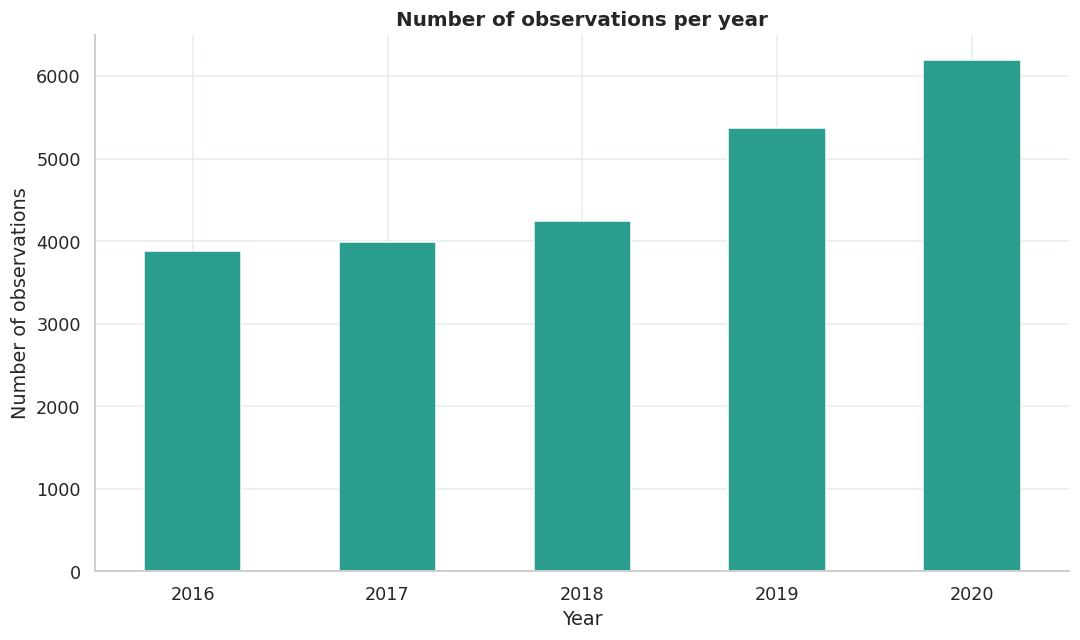

In [36]:
year_counts = df['year'].value_counts().sort_index()

year_counts.plot(kind='bar', figsize=(10, 6))
plt.title('Number of observations per year')
plt.xlabel('Year')
plt.ylabel('Number of observations')
plt.xticks(rotation=0)
plt.tight_layout()
save_chart("01_number_of_observations_per_year.png")


There's an increase in the number of observations over the years but between 2016 and 2018 the dataset has roughly consistent coverage. 2020 has the highest observation (2000 more than 2016)

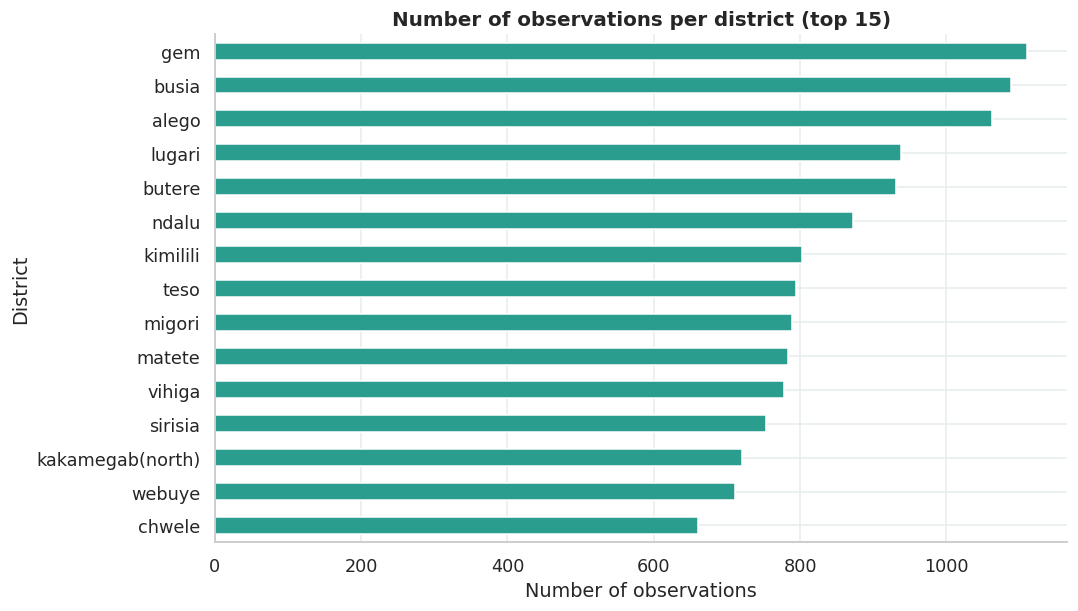

In [37]:
top_districts = df['district'].value_counts().head(15).sort_values(ascending=True)
top_districts.plot(kind='barh', figsize=(10, 6))
plt.title('Number of observations per district (top 15)')
plt.xlabel('Number of observations')
plt.ylabel('District')
save_chart("02_number_of_observations_per_district_top_15.png")
plt.show()

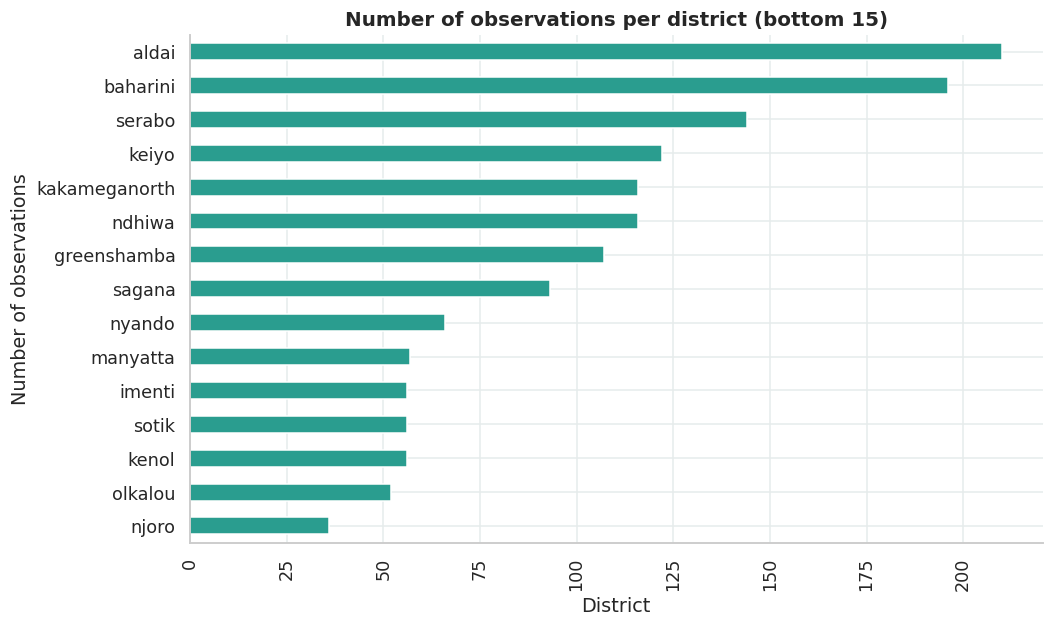

In [38]:
bottom_districts = df['district'].value_counts().tail(15).sort_values(ascending=True)

bottom_districts.plot(kind='barh', figsize=(10, 6))
plt.title('Number of observations per district (bottom 15)')
plt.xlabel('District')
plt.ylabel('Number of observations')
plt.xticks(rotation=90)
save_chart("03_number_of_observations_per_district_bottom_15.png")
plt.show()

Districts in western region of Kenya have the highest coverage with Gem, Busia, and Alego leading. The distribution is very uneven. Some have 1000+ observations and other have less than 50.

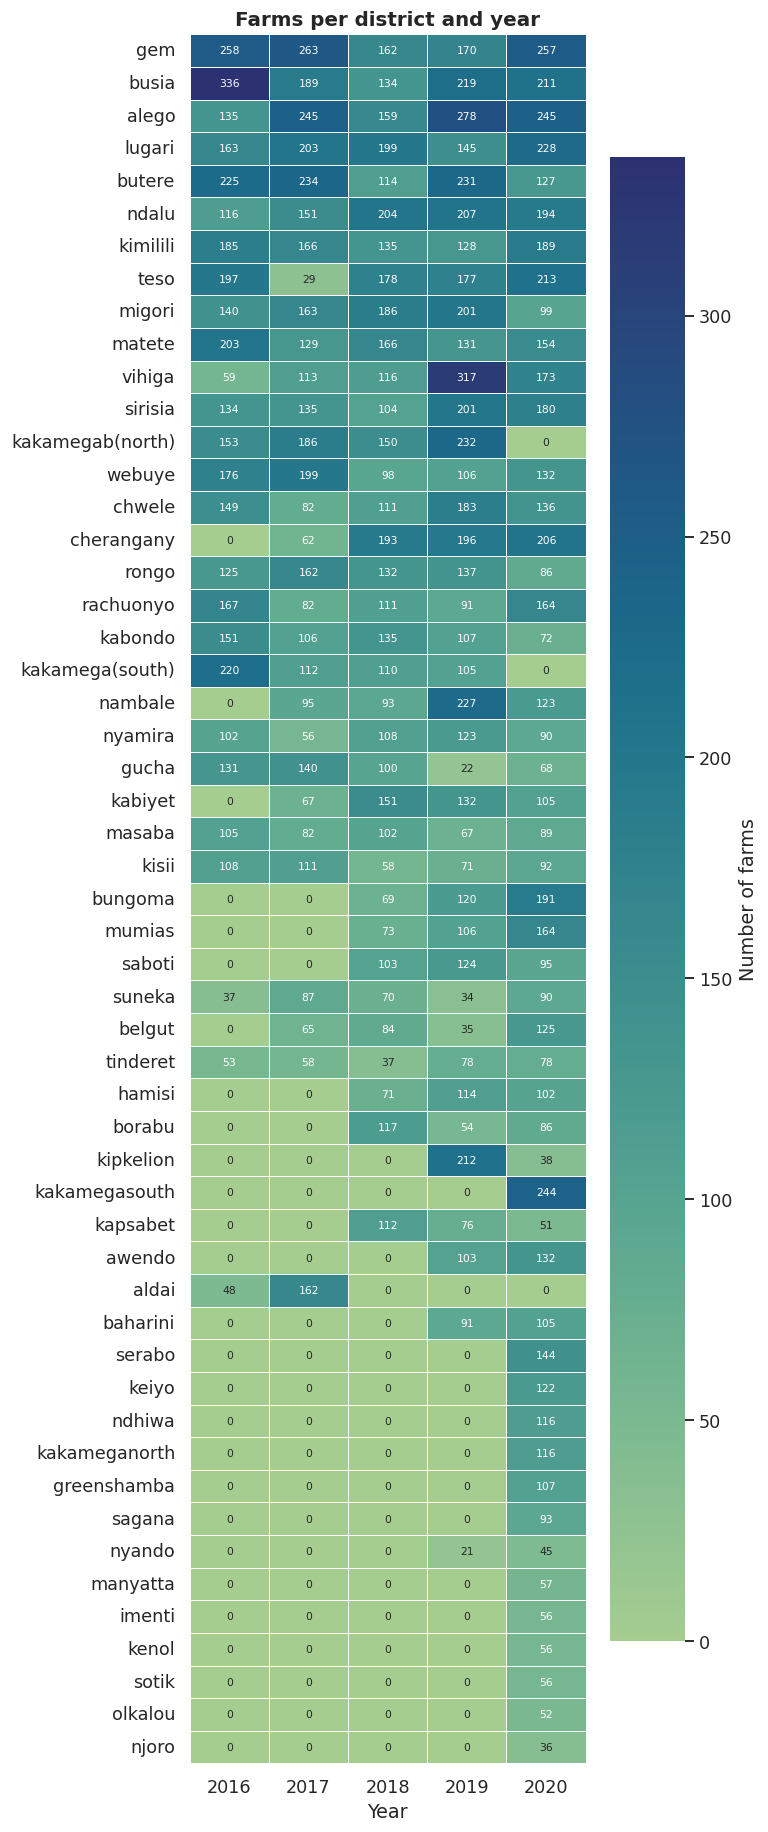

In [39]:
year_district_counts = pd.crosstab(df["district"], df["year"])
year_district_counts = year_district_counts.loc[
    year_district_counts.sum(axis=1).sort_values(ascending=False).index
]

plt.figure(figsize=(7, 0.28 * len(year_district_counts) + 2))
ax = sns.heatmap(
    year_district_counts,
    annot=True, fmt="d", annot_kws={"size": 7},
    cmap="crest",
    linewidths=0.4, linecolor="white",
    cbar_kws={"label": "Number of farms"},
)
ax.grid(False)
ax.set_title("Farms per district and year")
ax.set_xlabel("Year")
ax.set_ylabel("")
plt.tight_layout()
save_chart("04_farms_per_district_and_year.png")
plt.show()

Observations are unevenly distributed across districts and district coverage varies by year. I'll need to interpret any changes observed over time alongside changes in the geographic coverage of the survey sample

## Yield distribution

In [40]:
df['yield_kg_pa'].describe()

count    23674.000000
mean      1274.614642
std        683.595310
min          0.000000
25%        789.473690
50%       1185.925500
75%       1662.894750
max       4100.000000
Name: yield_kg_pa, dtype: float64

In [41]:
df['yield_kg_pa'].isna().sum()

np.int64(0)

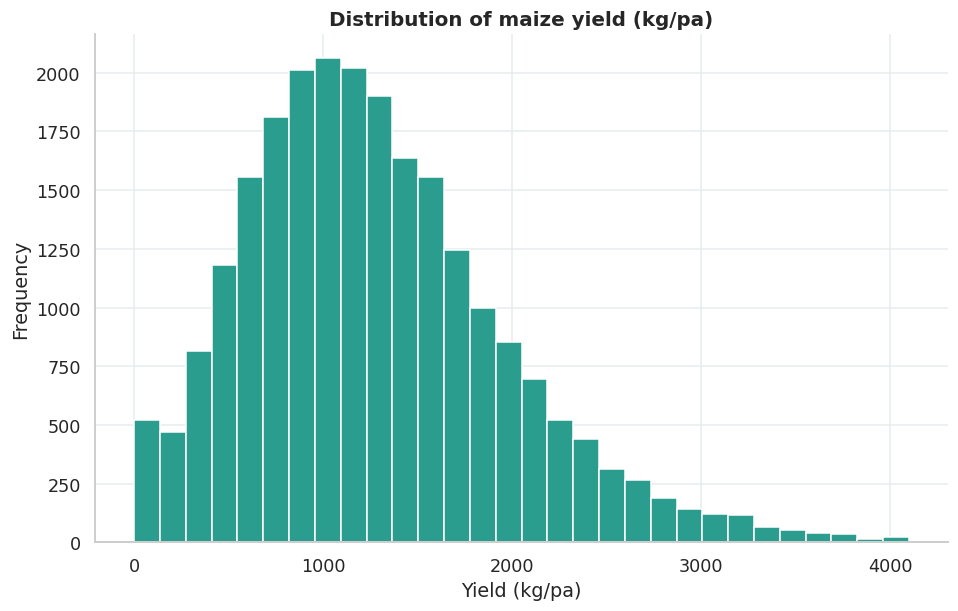

In [42]:
plt.figure(figsize=(10, 6))

plt.hist(df['yield_kg_pa'].dropna(), bins=30)

plt.title('Distribution of maize yield (kg/pa)')
plt.xlabel('Yield (kg/pa)')
plt.ylabel('Frequency')
save_chart("05_distribution_of_maize_yield_kg_pa.png")
plt.show()

In [43]:
print("Zero yield:", (df["yield_kg_pa"] == 0).sum())
print("Missing yield:", df["yield_kg_pa"].isna().sum())

Zero yield: 326
Missing yield: 0


It has a light skew in the right extending to 4000+. Yield contains 326 zero observations (1.4%), which I retained because zero production may be  crop failure.

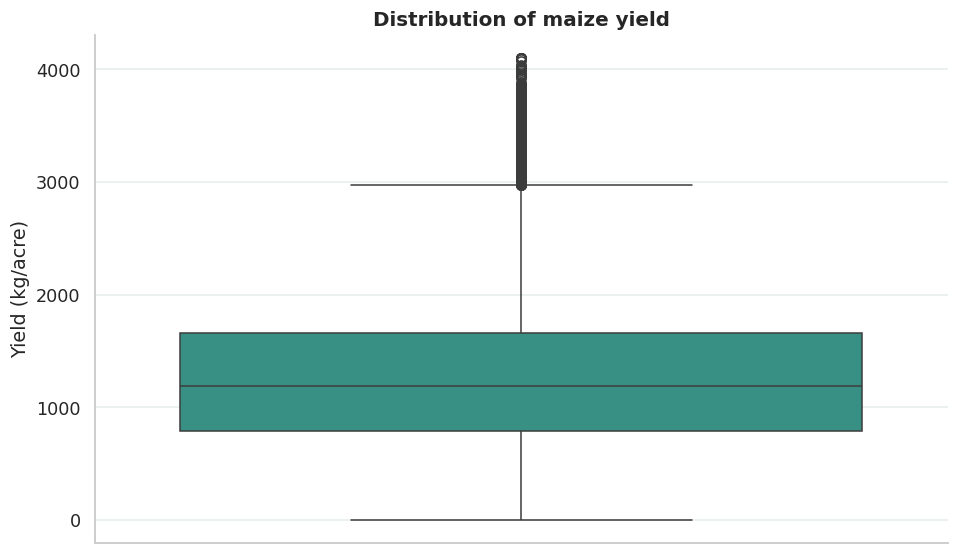

In [44]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df['yield_kg_pa'].dropna(),
)

plt.title('Distribution of maize yield')
plt.ylabel('Yield (kg/acre)')
save_chart("06_distribution_of_maize_yield.png")
plt.show()

In [45]:
yield_by_year = df.groupby("year")["yield_kg_ph"].agg(
    ["mean", "median"]
)

print(yield_by_year)

             mean     median
year                        
2016  2821.925749  2620.6130
2017  3507.426371  3303.4036
2018  3184.293639  2916.5928
2019  3126.597391  2902.7043
2020  3120.381947  2965.2026


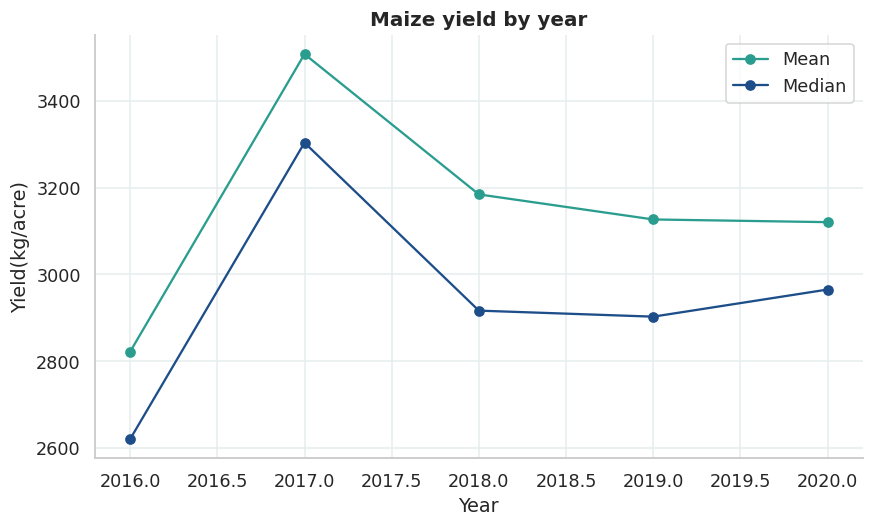

In [46]:
yield_by_year.plot(
    kind='line',
    marker='o',
    figsize=(9,5)
)


plt.title('Maize yield by year')
plt.xlabel('Year')
plt.ylabel('Yield(kg/acre)')
plt.legend(['Mean', 'Median'])
save_chart("07_maize_yield_by_year.png")
plt.show()

Yield peaked in 2017, declined through 2019, and showed a modest recovery in 2020.

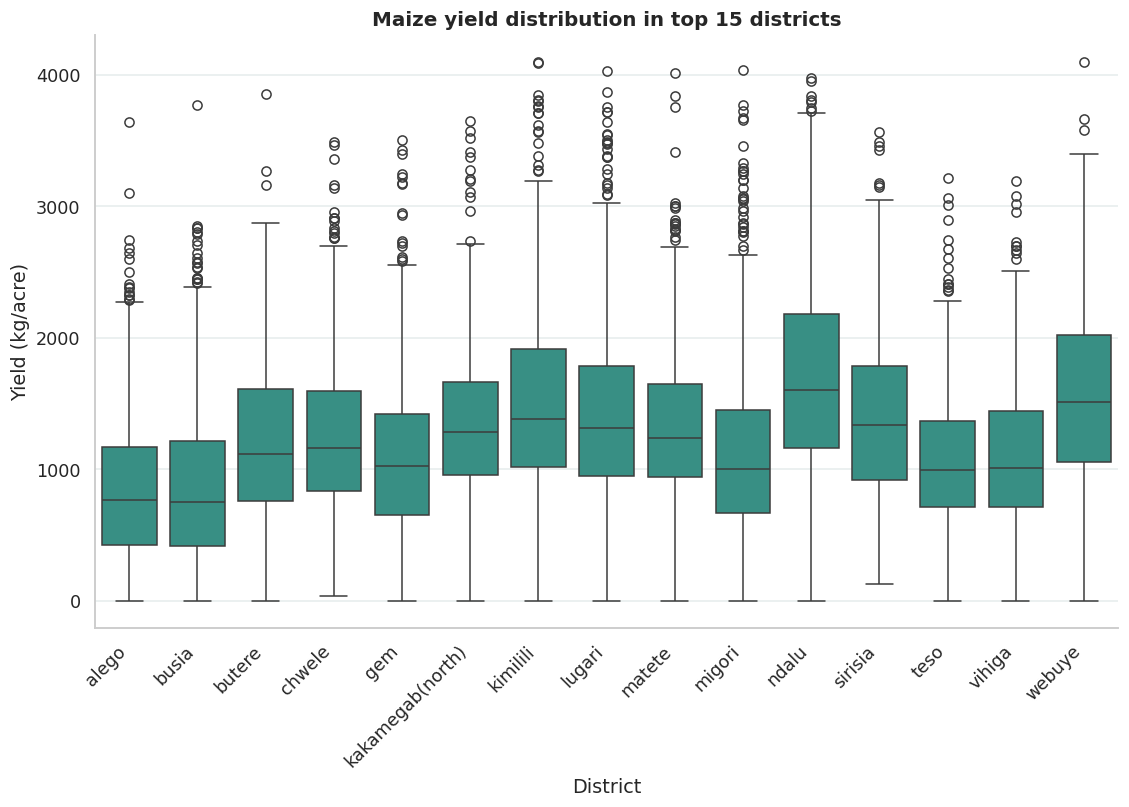

In [47]:
top_15_districts = df["district"].value_counts().head(15).index

district_data = df[
    df["district"].isin(top_15_districts)
]

plt.figure(figsize=(12, 7))

sns.boxplot(
    data=district_data,
    x="district",
    y="yield_kg_pa"
)

plt.title("Maize yield distribution in top 15 districts")
plt.xlabel("District")
plt.ylabel("Yield (kg/acre)")
plt.xticks(rotation=45, ha="right")
save_chart("08_maize_yield_distribution_in_top_15_districts.png")
plt.show()

The boxes are fairly wide, meaning yield varies a lot among farmers in the same district. So district alone clearly doesn't explain all the differences in yield.

There are many points above 3,000 kg/ha, and several reach around 4,000–4,100 kg/ha but they aren't isolated to one district.

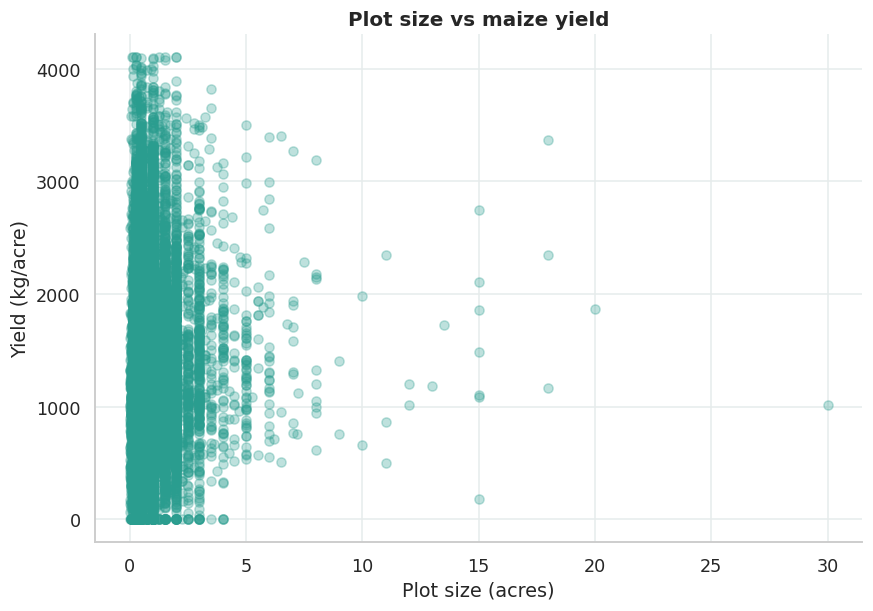

In [48]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df["plot_acres"],
    df["yield_kg_pa"],
    alpha=0.3
)

plt.title("Plot size vs maize yield")
plt.xlabel("Plot size (acres)")
plt.ylabel("Yield (kg/acre)")
save_chart("09_plot_size_vs_maize_yield.png")
plt.show()

The vast majority of plots are below about 3 acres, with only a small number extending beyond 5 acres. Surprisingly, there's not a linear relationship between plot size and yield which makes sense because the yield is already standardized by area.

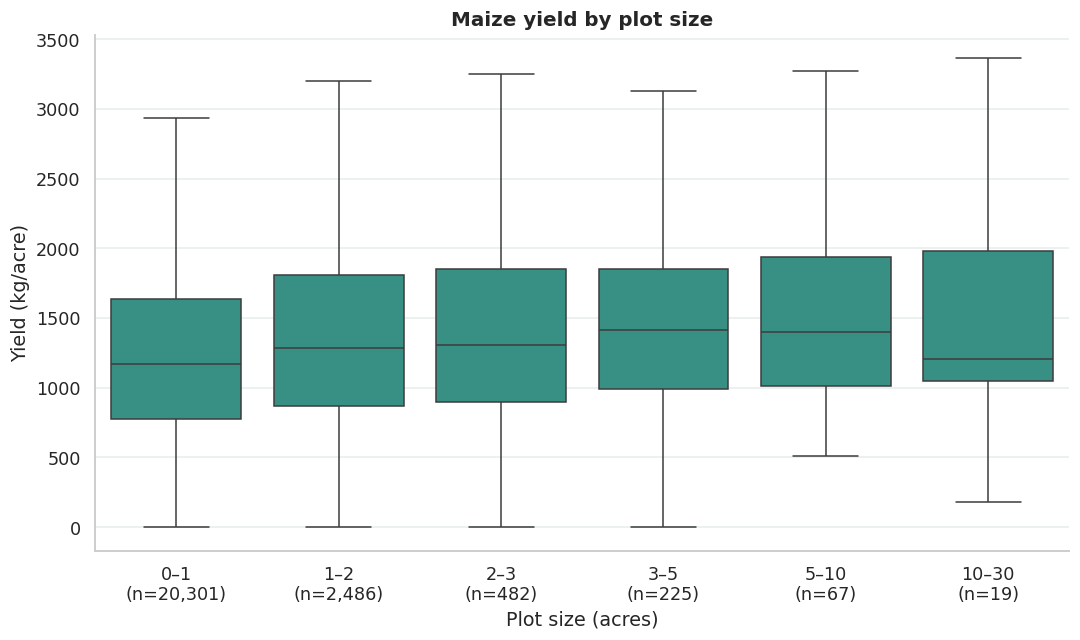

In [49]:
bins = [0, 1, 2, 3, 5, 10, 30]
order = ["0–1", "1–2", "2–3", "3–5", "5–10", "10–30"]

df["plot_size_group"] = pd.cut(df["plot_acres"], bins=bins, labels=order,
                               include_lowest=True)

counts = df["plot_size_group"].value_counts().reindex(order)
labels = [f"{g}\n(n={counts[g]:,})" for g in order]

plt.figure(figsize=(10, 6))
ax = sns.boxplot(
    data=df,
    x="plot_size_group",
    y="yield_kg_pa",
    order=order,
    showfliers=False,   # hide outliers so the boxes are readable
)

ax.set_xticks(range(len(order)))
ax.set_xticklabels(labels)
ax.set_title("Maize yield by plot size")
ax.set_xlabel("Plot size (acres)")
ax.set_ylabel("Yield (kg/acre)")
plt.tight_layout()
save_chart("10_maize_yield_by_plot_size.png")
plt.show()

Median yield varies only modestly with plot size, peaking at 3-10 acres, so plot size is a weak driver of yield

District, year and plot size explain only a little of why one farm yields more than another. So next step is to look at farming practices.

## Fertilizer 

Compare yield for dap_kg_pa, can_kg_pa, urea_kg_pa and npk_kg_pa.

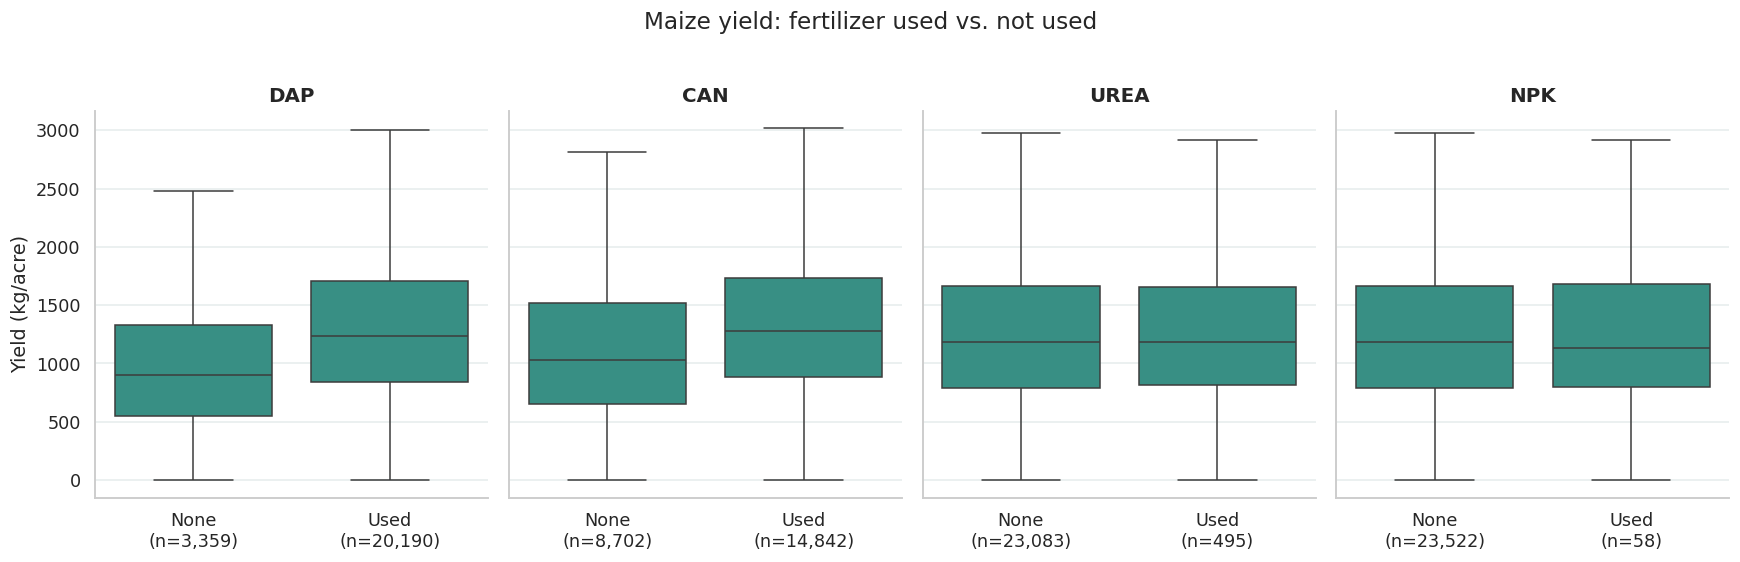

In [50]:
# Any vs none

fert_cols = ["dap_kg_pa", "can_kg_pa", "urea_kg_pa", "npk_kg_pa"]

df["fert_total_kg_pa"] = df[fert_cols].sum(axis=1, min_count=1)

fig, axes = plt.subplots(1, 4, figsize=(16, 5), sharey=True)

for ax, col in zip(axes, fert_cols):
    used = np.where(df[col] > 0, "Used", "None")
    used = pd.Series(used, index=df.index).where(df[col].notna())
    tmp = df.assign(used=used).dropna(subset=["used"])

    order = ["None", "Used"]
    counts = tmp["used"].value_counts().reindex(order).fillna(0).astype(int)

    sns.boxplot(data=tmp, x="used", y="yield_kg_pa", order=order,
                showfliers=False, ax=ax)
    ax.set_xticks(range(2))
    ax.set_xticklabels([f"{g}\n(n={counts[g]:,})" for g in order])
    ax.set_title(col.replace("_kg_pa", "").upper())
    ax.set_xlabel("")
    ax.set_ylabel("Yield (kg/acre)" if ax is axes[0] else "")

fig.suptitle("Maize yield: fertilizer used vs. not used", y=1.02)
plt.tight_layout()
save_chart("11_maize_yield_fertilizer_used_vs_not_used.png")
plt.show()

DAP is the strongest signal so far. It  raises median yield by ~38% overall (900 → 1,240 kg/acre). It is also well populated on both sides (3,359 vs. 20,221). Again, since there's a georgraphical differences, want to see if the effect holds, if we keep district constant.

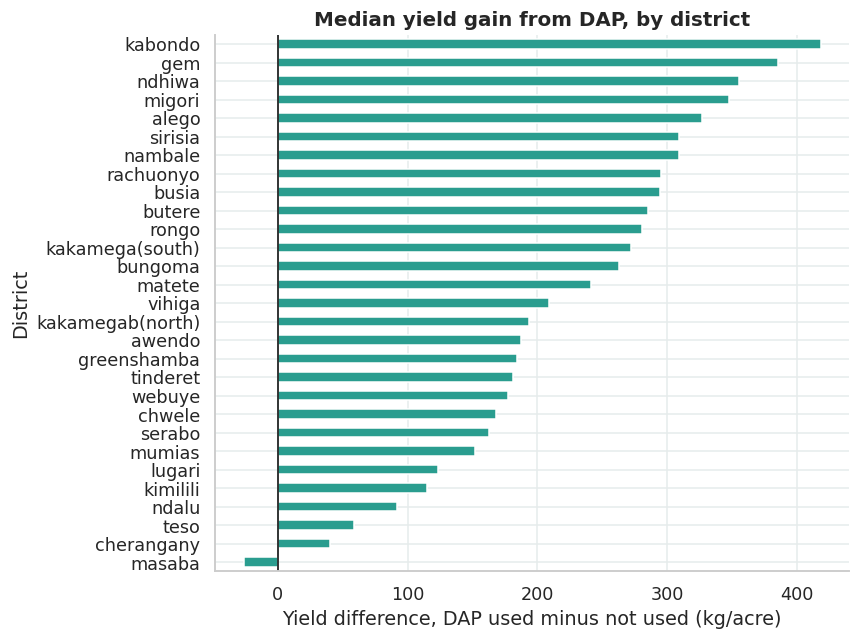

In [51]:
# Does the DAP gap hold inside districts?
df["dap_used"] = df["dap_kg_pa"] > 0

# Median yield by district and DAP use
med = df.groupby(["district", "dap_used"])["yield_kg_pa"].median().unstack()
n = df.groupby(["district", "dap_used"]).size().unstack()

# Keep districts with at least 30 farms in both groups
keep = (n[True] >= 30) & (n[False] >= 30)
gap = (med.loc[keep, True] - med.loc[keep, False]).sort_values()

plt.figure(figsize=(8, 6))
gap.plot(kind="barh")
plt.axvline(0, color="black", linewidth=1)
plt.title("Median yield gain from DAP, by district")
plt.xlabel("Yield difference, DAP used minus not used (kg/acre)")
plt.ylabel("District")
plt.tight_layout()
save_chart("12_median_yield_gain_from_dap_by_district.png")
plt.show()

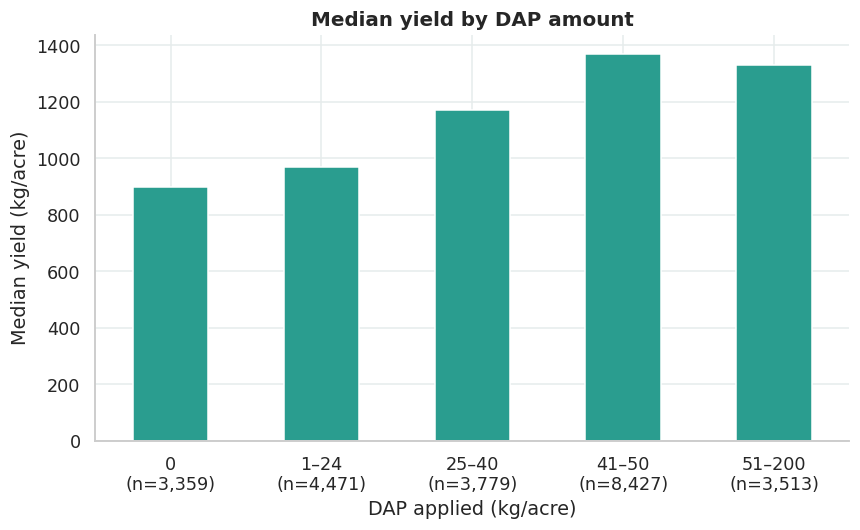

In [52]:
# does yield keep rising with kg/acre, or flatten at the usual rate
d = df.dropna(subset=["dap_kg_pa"]).copy()

bins = [-1, 0, 24, 40, 50, 200]
labels = ["0", "1–24", "25–40", "41–50", "51–200"]

df["dap_bin"] = pd.cut(d["dap_kg_pa"], bins=bins, labels=labels)

med = df.groupby("dap_bin", observed=True)["yield_kg_pa"].median()
n = df["dap_bin"].value_counts().reindex(labels)

ax = med.plot(kind="bar", figsize=(8, 5))
ax.set_xticklabels([f"{l}\n(n={n[l]:,})" for l in labels], rotation=0)
ax.set_title("Median yield by DAP amount")
ax.set_xlabel("DAP applied (kg/acre)")
ax.set_ylabel("Median yield (kg/acre)")
plt.tight_layout()
save_chart("13_median_yield_by_dap_amount.png")
plt.show()

In [53]:
m = df.groupby(df["dap_kg_pa"] > 0)["yield_kg_pa"].median()
print(m)
print(f"gain: {(m[True] - m[False]) / m[False]:.1%}")

dap_kg_pa
False     904.90051
True     1236.51000
Name: yield_kg_pa, dtype: float64
gain: 36.6%


In [54]:
d["dap_used"] = (d["dap_kg_pa"] > 0).astype(float)

g = (d.groupby(["district", "year", "dap_used"])["yield_kg_pa"]
       .agg(["median", "size"]).unstack("dap_used"))

keep = (g[("size", 0.0)] >= 20) & (g[("size", 1.0)] >= 20)
gap = g.loc[keep, ("median", 1.0)] - g.loc[keep, ("median", 0.0)]

print("district-year cells:", keep.sum())
print("share where DAP is higher:", f"{(gap > 0).mean():.0%}")
print("median gap (kg/acre):", round(gap.median()))

district-year cells: 60
share where DAP is higher: 95%
median gap (kg/acre): 283


### DAP and yield

DAP raises median yield by about 36.6%, and the gain levels off near 50 kg/acre as seen in the median yield by DAP amount.

- **Any vs. none:** median yield is ~900 kg/acre without DAP (n=3,359) and ~1,240 with it (n=20,221), ~37%.
- **Districts:** 28 of 29 districts show a positive gap, typically +150 to +350 kg/acre. Masaba (−40) is the only exception (but it has few farms).
- **Median yield by DAP amount:** yield rises from ~900 (none) to ~970 (≤24 kg/acre), ~1,170 (25–40) and ~1,365 (41–50), then flattens at ~1,325 above 50.
- **Within districts:** 95% of cells are positive. DAP beats no DAP in about 57 of 60 district-year cells.

Limits: low doses (under 24 kg/acre) add little, the gain above 50 kg/acre rests on few farms.

### Lime and yield

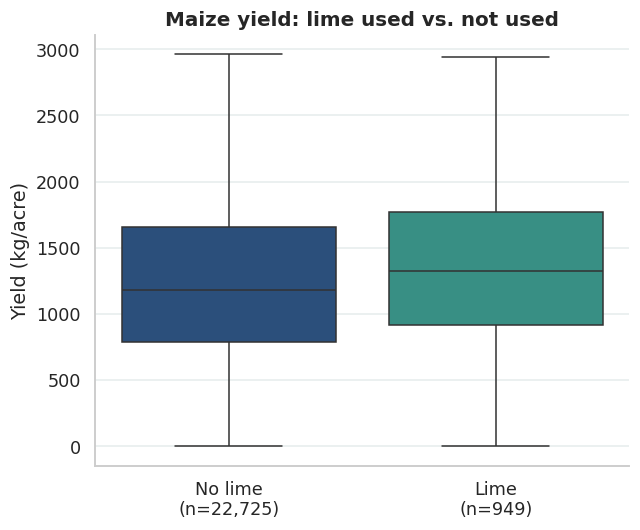

lime_kg_pa
False    1182.0
True     1321.0
Name: yield_kg_pa, dtype: float64


In [55]:
lime = df["lime_kg_pa"].gt(0).map({False: "No lime", True: "Lime"})
order = ["No lime", "Lime"]
counts = lime.value_counts().reindex(order)
labels = [f"{g}\n(n={counts[g]:,})" for g in order]

plt.figure(figsize=(6, 5))
ax = sns.boxplot(x=lime, y=df["yield_kg_pa"], order=order, showfliers=False,
                 palette=["#1d4e89", "#2a9d8f"], hue=lime, legend=False)
ax.set_xticks(range(2))
ax.set_xticklabels(labels)
ax.set_title("Maize yield: lime used vs. not used")
ax.set_xlabel("")
ax.set_ylabel("Yield (kg/acre)")
plt.tight_layout()
save_chart("14_maize_yield_lime_used_vs_not_used.png")
plt.show()

print(df.groupby(df["lime_kg_pa"].gt(0))["yield_kg_pa"].median().round(0))

In [56]:
d = df.copy()
d["lime_used"] = d["lime_kg_pa"].gt(0).astype(float)

g = (d.groupby(["district", "year", "lime_used"])["yield_kg_pa"]
       .agg(["median", "size"]).unstack("lime_used"))

keep = (g[("size", 0.0)] >= 10) & (g[("size", 1.0)] >= 10)
gap = g.loc[keep, ("median", 1.0)] - g.loc[keep, ("median", 0.0)]

print("district-year cells:", keep.sum())
print("share where lime is higher:", f"{(gap > 0).mean():.0%}")
print("median gap (kg/acre):", round(gap.median()))

district-year cells: 31
share where lime is higher: 81%
median gap (kg/acre): 256


Lime goes with higher yield, and the gap is larger once you compare farms in the same district and year. This result is tentative because few farms use lime.

## Hybrid seeds

In [57]:
# Clean seed classification: built from the variety names, not the old hybrid flag
df["hybrid_clean"] = df["seed_class"].map({"local only": 0.0, "named hybrid": 1.0})  # mixed planters = NaN

print(df.groupby("seed_class")["yield_kg_pa"].agg(n="size", median="median").round(0))
print(df.groupby(["seed_class", "hybrid"])["yield_kg_pa"].agg(n="size", median="median").round(0))


                  n  median
seed_class                 
local only     4010   776.0
mixed          1487  1175.0
named hybrid  18083  1285.0
                         n  median
seed_class   hybrid               
local only   0.0      2731   776.0
             1.0      1279   776.0
mixed        1.0      1487  1175.0
named hybrid 0.0       231  1211.0
             1.0     17852  1287.0


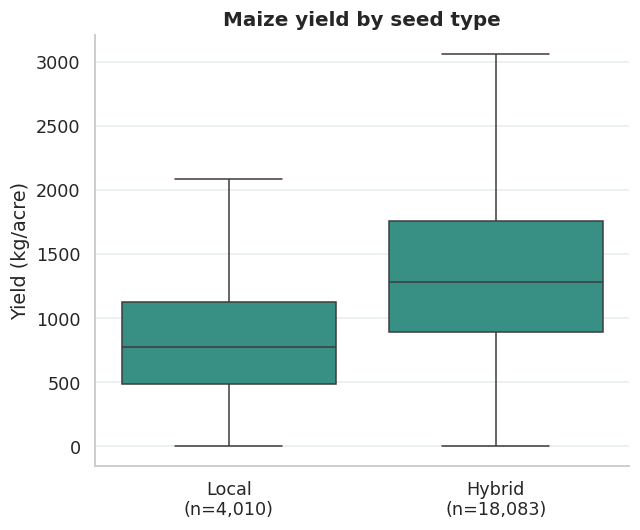

In [58]:
seed = df["seed_class"].map({"local only": "Local", "named hybrid": "Hybrid"})
order = ["Local", "Hybrid"]
counts = seed.value_counts().reindex(order)
labels = [f"{g}\n(n={counts[g]:,})" for g in order]


plt.figure(figsize=(6, 5))
ax = sns.boxplot(x=seed, y=df["yield_kg_pa"], order=order, showfliers=False)
ax.set_xticks(range(2))
ax.set_xticklabels(labels)
ax.set_title("Maize yield by seed type")
ax.set_xlabel("")
ax.set_ylabel("Yield (kg/acre)")
plt.tight_layout()
save_chart("15_maize_yield_by_seed_type.png")
plt.show()

In [59]:
m = df.groupby("hybrid_clean")["yield_kg_pa"].median()
print(m)
print(f"gain: {(m[1.0] - m[0.0]) / m[0.0]:.1%}")


hybrid_clean
0.0     775.62903
1.0    1284.84630
Name: yield_kg_pa, dtype: float64
gain: 65.7%


In [60]:
df["dap_used"] = df["dap_kg_pa"] > 0

table = (df.dropna(subset=["hybrid_clean", "dap_kg_pa"])
           .groupby(["hybrid_clean", "dap_used"])["yield_kg_pa"]
           .agg(n="count", median="median")
           .round(0))
print(table)


                           n  median
hybrid_clean dap_used               
0.0          False      1426   684.0
             True       2581   829.0
1.0          False      1674  1086.0
             True      16383  1304.0


In [61]:
d = df.dropna(subset=["hybrid_clean"])

g = (d.groupby(["district", "year", "hybrid_clean"])["yield_kg_pa"]
       .agg(["median", "size"]).unstack("hybrid_clean"))

keep = (g[("size", 0.0)] >= 20) & (g[("size", 1.0)] >= 20)
gap = g.loc[keep, ("median", 1.0)] - g.loc[keep, ("median", 0.0)]

print("district-year cells:", keep.sum())
print("share where hybrid is higher:", f"{(gap > 0).mean():.0%}")
print("median gap (kg/acre):", round(gap.median()))


district-year cells: 68
share where hybrid is higher: 100%
median gap (kg/acre): 373


## Hybrid seed and yield

Hybrid seed raises median yield by about [fill: cell 47]%, the largest effect of the factors checked so far.

- **How seed type is defined:** from the variety names farmers reported. The survey's own `hybrid` flag disagreed with the variety name for about 1,500 farms: 1,279 farms that named only a local variety were flagged hybrid, and 231 that named a hybrid were flagged non-hybrid. Those farms yield like their named variety (local-only farms: 776 kg/acre whichever way the flag says), so the names are right and the flag is not used.
- **Split:** 17% of farms plant only local seed (n=4,010), 77% plant a named hybrid (n=18,083), and 6% plant a mix (n=1,487). Mixed planters yield in between (median 1,175) and are left out of the comparison.
- **Overall:** median yield is 776 kg/acre with local seed and [fill: cell 47] with hybrid, +[fill]%.
- **Controlling for DAP:** hybrid wins both with and without it, [fill: cell 48].

| | No DAP | DAP |
|---|---|---|
| Local | [fill] | [fill] |
| Hybrid | [fill] | [fill] |

- **Together:** hybrid plus DAP beats local without DAP by [fill: cell 48]%.
- **Within district and year:** hybrid beats local in [fill]% of [fill] district-year cells (≥20 farms per side), with a median gap of [fill] kg/acre (cell 49).

Limits: the local, no-DAP cell is small, and mixed planters are excluded from the comparison.


## Weather

In [62]:
for c in ["drought", "flood", "FAW", "striga", "stemborer"]:
    print(c, df[c].value_counts(dropna=False).to_dict())

drought {0.0: 17354, 1.0: 6047, nan: 273}
flood {0.0: 16769, nan: 4114, 1.0: 2791}
FAW {nan: 11140, 1.0: 8648, 0.0: 3886}
striga {nan: 17535, 0.0: 4120, 1.0: 2019}
stemborer {nan: 16810, 0.0: 6015, 1.0: 849}


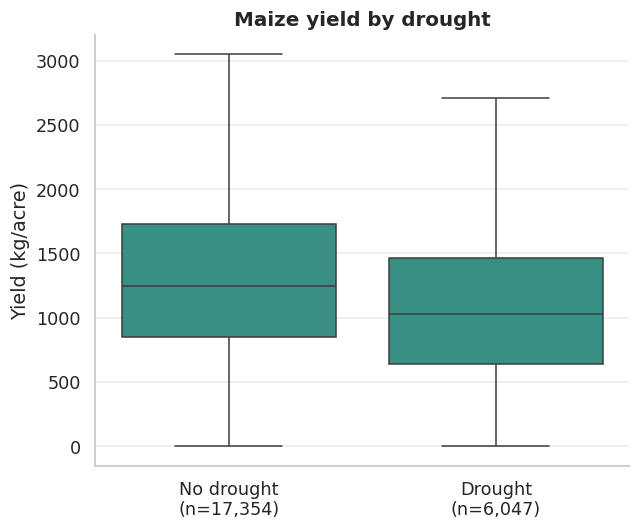

In [63]:
# drought has the best coverage
d = df.dropna(subset=["drought"]).copy()
d["drought"] = d["drought"].map({0.0: "No drought", 1.0: "Drought"})
order = ["No drought", "Drought"]
counts = d["drought"].value_counts().reindex(order)
labels = [f"{g}\n(n={counts[g]:,})" for g in order]

plt.figure(figsize=(6, 5))
ax = sns.boxplot(data=d, x="drought", y="yield_kg_pa", order=order, showfliers=False)
ax.set_xticks(range(2))
ax.set_xticklabels(labels)
ax.set_title("Maize yield by drought")
ax.set_xlabel("")
ax.set_ylabel("Yield (kg/acre)")
plt.tight_layout()
save_chart("16_maize_yield_by_drought.png")
plt.show()


In [64]:
m = df.groupby("drought")["yield_kg_pa"].median()
print(m)
print(f"gain: {(m[1.0] - m[0.0]) / m[0.0]:.1%}")

drought
0.0    1244.3787
1.0    1025.7412
Name: yield_kg_pa, dtype: float64
gain: -17.6%


Surprisingly both groups have crop failures. So drought doesn't explain the zero yields.

In [65]:
d = df.dropna(subset=["drought"])
print(d.groupby("year").agg(n=("drought", "size"),
                            drought_share=("drought", "mean"),
                            median_yield=("yield_kg_pa", "median")).round(2))

         n  drought_share  median_yield
year                                   
2016  3876           0.50       1060.53
2017  3804           0.24       1339.47
2018  4211           0.01       1180.31
2019  5371           0.50       1174.68
2020  6139           0.07       1199.98


In [66]:
# Drought share swings by year (50% in 2016 and 2019, 1% in 2018), so a pooled comparison mixes years.
# Comparing drought vs. no drought within each year instead.

med = d.groupby(["year", "drought"])["yield_kg_pa"].median().unstack()
n = d.groupby(["year", "drought"]).size().unstack()

out = pd.DataFrame({
    "n_no_drought": n[0.0],
    "n_drought": n[1.0],
    "median_no_drought": med[0.0].round(0),
    "median_drought": med[1.0].round(0),
    "gap": (med[1.0] - med[0.0]).round(0),
    "pct_gap": ((med[1.0] - med[0.0]) / med[0.0] * 100).round(1),
})
print(out)

      n_no_drought  n_drought  median_no_drought  median_drought    gap  \
year                                                                      
2016          1922       1954             1201.0           937.0 -264.0   
2017          2878        926             1397.0          1172.0 -225.0   
2018          4161         50             1180.0          1253.0   73.0   
2019          2661       2710             1315.0          1045.0 -270.0   
2020          5732        407             1208.0          1054.0 -155.0   

      pct_gap  
year           
2016    -22.0  
2017    -16.1  
2018      6.2  
2019    -20.6  
2020    -12.8  


In [67]:
d = df.dropna(subset=["drought"])

g = (d.groupby(["district", "year", "drought"])["yield_kg_pa"]
       .agg(["median", "size"]).unstack("drought"))

keep = (g[("size", 0.0)] >= 20) & (g[("size", 1.0)] >= 20)
gap = g.loc[keep, ("median", 1.0)] - g.loc[keep, ("median", 0.0)]

print("district-year cells:", keep.sum())
print("share where drought is lower:", f"{(gap < 0).mean():.0%}")
print("median gap (kg/acre):", round(gap.median()))

district-year cells: 64
share where drought is lower: 75%
median gap (kg/acre): -90


## Drought and yield

Drought lowers median yield by 12–22% in every year with enough data.

- **Overall:** median yield is 1244.3787 kg/acre without drought (n=17,354) and 1025 with it (n=6,047), 18%.
- **Year mix:** drought hit 50% of farms in 2016 and 2019, 24% in 2017, 7% in 2020 and 1% in 2018, so I compared within each year.
- **Within years:** drought lowers median yield by 150 to 270 kg/acre, a consistent drop of 12–22%.
- **Within district and year:** yield is lower with drought in 75% of 64 district-year cells (≥20 farms per side), with a median gap of −90 kg/acre. The larger within-year gaps (−150 to −270) show drought-hit farms are concentrated in districts that yield less for other reasons, such as poorer soil or lower inputs.
- **2018:** excluded, because only 50 farms reported drought.

| Year | No drought | Drought | Gap | % gap |
|---|---|---|---|---|
| 2016 | 1,201 (n=1,922) | 937 (n=1,954) | −264 | −22.0% |
| 2017 | 1,397 (n=2,878) | 1,172 (n=926) | −225 | −16.1% |
| 2019 | 1,315 (n=2,659) | 1,045 (n=2,707) | −270 | −20.5% |
| 2020 | 1,211 (n=5,631) | 1,061 (n=398) | −150 | −12.4% |

Limits: drought is farmer-reported, not measured rainfall. Drought does not explain the zero-yield farms, since they appear both with and without it.

In [68]:
col = "flood"
d = df.dropna(subset=[col])

med = d.groupby(["year", col])["yield_kg_pa"].median().unstack()
n = d.groupby(["year", col]).size().unstack()

out = pd.DataFrame({
    "n_no": n[0.0],
    f"n_{col}": n[1.0],
    "median_no": med[0.0].round(0),
    f"median_{col}": med[1.0].round(0),
    "gap": (med[1.0] - med[0.0]).round(0),
    "pct_gap": ((med[1.0] - med[0.0]) / med[0.0] * 100).round(1),
})
print(out)

        n_no  n_flood  median_no  median_flood    gap  pct_gap
year                                                          
2016     NaN     35.0        NaN        1047.0    NaN      NaN
2017  3619.0    185.0     1358.0         955.0 -403.0    -29.7
2018  3418.0    793.0     1200.0        1124.0  -76.0     -6.3
2019  4873.0    498.0     1172.0        1203.0   31.0      2.6
2020  4859.0   1280.0     1217.0        1104.0 -112.0     -9.2


In [69]:
d = df.dropna(subset=["flood"])

g = (d.groupby(["district", "year", "flood"])["yield_kg_pa"]
       .agg(["median", "size"]).unstack("flood"))

keep = (g[("size", 0.0)] >= 20) & (g[("size", 1.0)] >= 20)
gap = g.loc[keep, ("median", 1.0)] - g.loc[keep, ("median", 0.0)]

print("district-year cells:", keep.sum())
print("share where flood is lower:", f"{(gap < 0).mean():.0%}")
print("median gap (kg/acre):", round(gap.median()))

district-year cells: 51
share where flood is lower: 65%
median gap (kg/acre): -64


### Flood and yield

Flood has a small negative effect on median yield, about 64 kg/acre once district and year are held fixed.

- **Within district and year:** yield is lower with flood in 65% of 51 district-year cells (≥20 farms per side), with a median gap of −64 kg/acre.
- **Within years only:** the gap is inconsistent across years: −30% (2017, n=185 flood farms), −6% (2018), +3% (2019) and −9% (2020). 2016 is excluded because no farms were recorded as flood-free.

| Year | No flood | Flood | Gap | % gap |
|---|---|---|---|---|
| 2017 | 1,358 (n=3,619) | 955 (n=185) | −403 | −29.7% |
| 2018 | 1,200 (n=3,418) | 1,124 (n=793) | −76 | −6.3% |
| 2019 | 1,172 (n=4,873) | 1,203 (n=498) | +31 | +2.6% |
| 2020 | 1,217 (n=4,859) | 1,104 (n=1,280) | −112 | −9.2% |

Limits: flood is farmer-reported and 17% of farms have no answer.

In [70]:
df[['FAW', 'striga', 'stemborer']].describe()

,FAW,striga,stemborer
count,12534.000000,6139.000000,6864.000000
mean,0.689963,0.328881,0.123689
std,0.462527,0.469845,0.329250
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000
50%,1.000000,0.000000,0.000000
75%,1.000000,1.000000,0.000000
max,1.000000,1.000000,1.000000


2020 is the only usable year. 6,190 farms answered and 37% were affected (about 2,290 farms), so both groups are large.

In [71]:
pest_cols = ['FAW', 'striga', 'stemborer']

for col in pest_cols:
    d = df[df[col].notna()]

    print(d.groupby(col)["yield_kg_pa"].agg(n="size", median="median").round(0))

        n  median
FAW              
0.0  3886  1215.0
1.0  8648  1211.0
           n  median
striga              
0.0     4120  1273.0
1.0     2019  1040.0
              n  median
stemborer              
0.0        6015  1198.0
1.0         849  1216.0


In [72]:
for c in ["fertility", "slope"]:
    print(c, df[c].value_counts(dropna=False).to_dict())

fertility {'same': 9978, 'better': 6078, nan: 4149, 'worse': 1738, 'dont_know': 1207, 'this_is_the_only_field_i_farm': 524}
slope {nan: 19227, 'midslope': 1652, 'footslope': 1153, 'shoulder': 873, 'hilltop': 400, 'valley': 369}


In [73]:
for c in ["fertility", "slope"]:
    print(c, df[c].value_counts(dropna=False).to_dict())

fertility {'same': 9978, 'better': 6078, nan: 4149, 'worse': 1738, 'dont_know': 1207, 'this_is_the_only_field_i_farm': 524}
slope {nan: 19227, 'midslope': 1652, 'footslope': 1153, 'shoulder': 873, 'hilltop': 400, 'valley': 369}


Slope is 80% missing.
Fertility compares the farm to the other plots farmed by the farmer

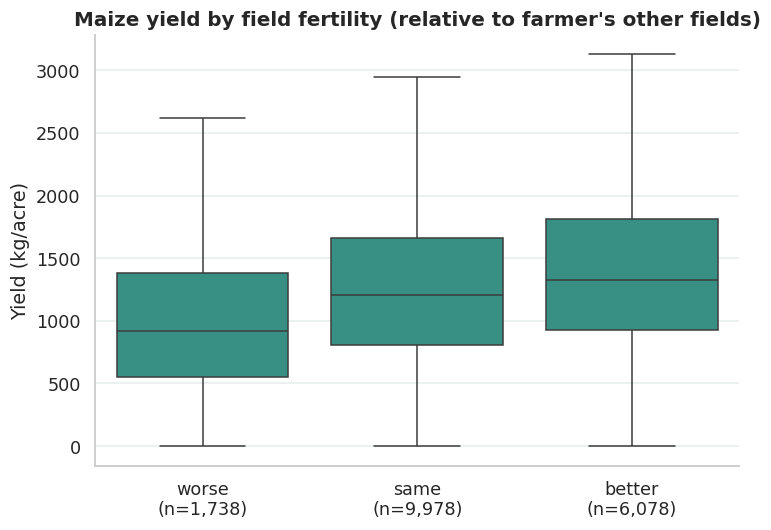

In [74]:
order = ["worse", "same", "better"]
f = df[df["fertility"].isin(order)]

counts = f["fertility"].value_counts().reindex(order)
labels = [f"{g}\n(n={counts[g]:,})" for g in order]

plt.figure(figsize=(7, 5))
ax = sns.boxplot(data=f, x="fertility", y="yield_kg_pa", order=order, showfliers=False)
ax.set_xticks(range(3))
ax.set_xticklabels(labels)
ax.set_title("Maize yield by field fertility (relative to farmer's other fields)")
ax.set_xlabel("")
ax.set_ylabel("Yield (kg/acre)")
plt.tight_layout()
save_chart("17_maize_yield_by_field_fertility_relative_to_farmer.png")
plt.show()

In [75]:
f = df[df["fertility"].isin(["worse", "better"])].copy()
f["better"] = (f["fertility"] == "better").astype(float)

# exact pooled medians
print(f.groupby("fertility")["yield_kg_pa"].median().round(0))

# within district-year cells
g = (f.groupby(["district", "year", "better"])["yield_kg_pa"]
       .agg(["median", "size"]).unstack("better"))

keep = (g[("size", 0.0)] >= 20) & (g[("size", 1.0)] >= 20)
gap = g.loc[keep, ("median", 1.0)] - g.loc[keep, ("median", 0.0)]

print("district-year cells:", keep.sum())
print("share where better is higher:", f"{(gap > 0).mean():.0%}")
print("median gap (kg/acre):", round(gap.median()))

fertility
better    1329.0
worse      922.0
Name: yield_kg_pa, dtype: float64
district-year cells: 26
share where better is higher: 96%
median gap (kg/acre): 346


In [76]:
f = df[df["fertility"].isin(["worse", "same", "better"])]
print(f.groupby("fertility").agg(
    dap_share=("dap_kg_pa", lambda s: (s > 0).mean()),
    hybrid_share=("hybrid_clean", "mean"),
).round(2))


           dap_share  hybrid_share
fertility                         
better          0.87          0.86
same            0.85          0.81
worse           0.78          0.73


### Field fertility and yield

Fields the farmer rates as more fertile than their other fields yield about 44% more at the median, and the gap holds within district and year.

- **Coding:** farmers rated this field `better`, `same` or `worse` than their other fields. `dont_know` and `this_is_the_only_field_i_farm` (1,731 farms) are excluded, and 17% of farms have no answer.
- **Overall:** median yield is 922 kg/acre for `worse` (n=1,738), about 1,200 for `same` (n=9,978) and 1,329 for `better` (n=6,078).
- **Better vs. worse:** +407 kg/acre (+44%).
- **Within district and year:** `better` has the higher median in 96% of 26 district-year cells (≥20 farms per side), with a median gap of +346 kg/acre.
- **Overlap with inputs:** better fields use DAP and hybrid only slightly more often than worse fields (DAP 87% vs. 78%, hybrid 91% vs. 84%), so the gap is not an input effect in disguise.

Limits: the rating is relative to the farmer's own fields, not a soil measurement.

In [77]:
print(df.groupby("year")["slope"].agg(n_recorded="count"))
print(df["slope"].value_counts())

      n_recorded
year            
2016           0
2017         503
2018        1174
2019        1407
2020        1363
slope
midslope     1652
footslope    1153
shoulder      873
hilltop       400
valley        369
Name: count, dtype: int64


### Slope

Not analysed in depth: only 19% of farms (4,447) have a slope recorded, across 2017–2020, split into five positions (369–1,652 farms each). Too sparse to control for district and year.

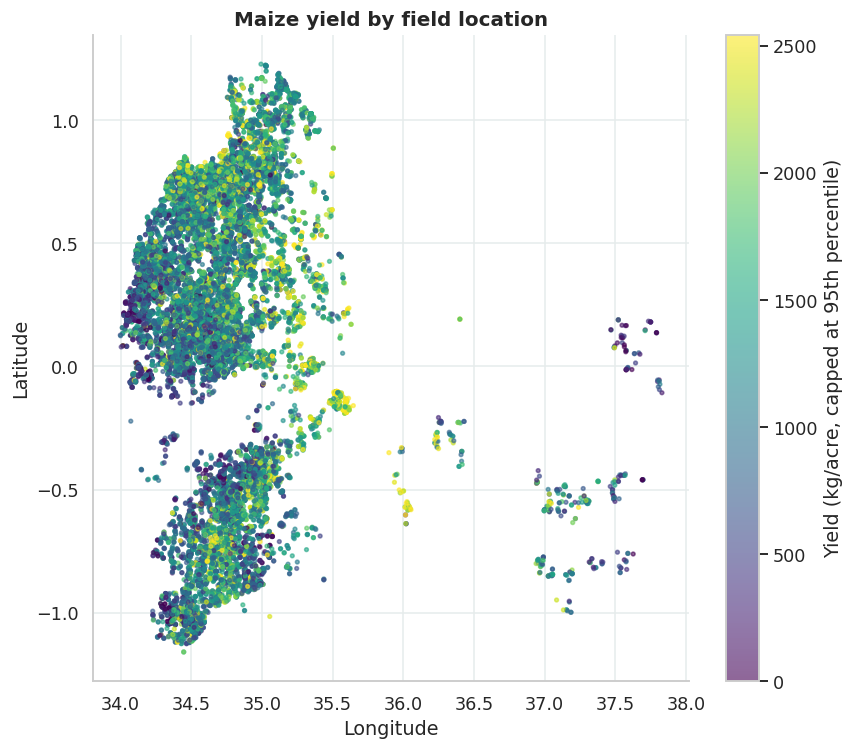

In [78]:
coord = df.dropna(subset=["field_latitude", "field_longitude"])

plt.figure(figsize=(8, 7))
sc = plt.scatter(coord["field_longitude"], coord["field_latitude"],
                 c=coord["yield_kg_pa"].clip(upper=coord["yield_kg_pa"].quantile(0.95)),
                 s=6, cmap="viridis", alpha=0.6)
plt.colorbar(sc, label="Yield (kg/acre, capped at 95th percentile)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Maize yield by field location")
plt.tight_layout()
save_chart("18_maize_yield_by_field_location.png")
plt.show()

Fields side by side often differ from very low to very high yield, so farm-level factors matter more than region.

Low-yield (dark) clusters appear in the far west (around 34.1 to 34.3°E, 0.1 to 0.3°N) and the south-west (around 34.3 to 34.6°E, −1.0°S). High-yield clusters appear at about 34.5 to 35.0°E, 0.5 to 0.8°N.



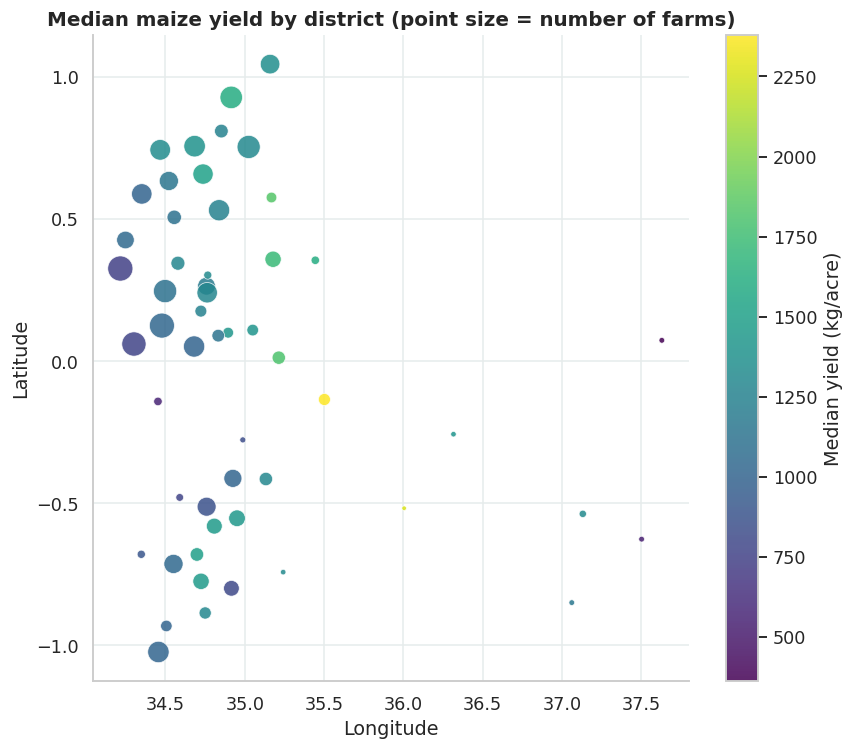

count      53.0
mean     1230.0
std       378.0
min       361.0
25%      1009.0
50%      1244.0
75%      1408.0
max      2380.0
Name: median_yield, dtype: float64


In [79]:

dist = (coord.groupby("district")
          .agg(lat=("field_latitude", "mean"),
               lon=("field_longitude", "mean"),
               median_yield=("yield_kg_pa", "median"),
               n=("yield_kg_pa", "size")))
dist = dist[dist["n"] >= 30]

plt.figure(figsize=(8, 7))
sc = plt.scatter(dist["lon"], dist["lat"], c=dist["median_yield"],
                 s=dist["n"] / 4, cmap="viridis", alpha=0.85,
                 edgecolor="white", linewidth=0.5)
plt.colorbar(sc, label="Median yield (kg/acre)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Median maize yield by district (point size = number of farms)")
plt.tight_layout()
save_chart("19_median_maize_yield_by_district_point_size_number_o.png")
plt.show()

print(dist["median_yield"].describe().round(0))

In [80]:
y = df["yield_kg_pa"]
district_mean = df.groupby("district")["yield_kg_pa"].transform("mean")
r2 = 1 - ((y - district_mean) ** 2).sum() / ((y - y.mean()) ** 2).sum()
print(f"share of yield variation explained by district: {r2:.0%}")

share of yield variation explained by district: 18%


District alone accounts for about 18% of the variance in farm yield, and median yield ranges from about 700 to 1,750 kg/acre across well-sampled districts, with a mild rise from west to east. The remaining ~82% is variation between farms within the same district.

- **Farm map:** at farm level, colours mix with no smooth regions, because yield varies strongly within a place.


In [81]:
cands = ["weed", "pesticide", "intercrop", "compost", "comp_kg_pa", "lime_kg_pa",
         "growing_days", "plants_sqm_spacing", "row_spacing", "plant_spacing",
         "seed_depth_num", "seed_type", "prev_season_yield", "cows", "oxen",
         "goats", "hh_num", "distance_meter", "termites", "comp_quality"]

print(df.groupby("year")[cands].apply(lambda g: g.notna().mean()).T.round(2))

year                2016  2017  2018  2019  2020
weed                0.00  1.00  0.99  1.00  0.99
pesticide           0.00  0.85  0.52  0.68  0.41
intercrop           1.00  1.00  1.00  1.00  1.00
compost             1.00  0.95  0.60  0.56  0.99
comp_kg_pa          1.00  1.00  1.00  1.00  0.00
lime_kg_pa          1.00  1.00  1.00  1.00  0.98
growing_days        0.00  0.39  0.98  0.96  0.90
plants_sqm_spacing  0.00  0.00  0.00  0.00  0.99
row_spacing         0.45  0.99  0.59  0.55  0.00
plant_spacing       0.00  0.99  0.59  0.55  0.00
seed_depth_num      0.00  0.00  0.88  0.00  0.00
seed_type           1.00  1.00  1.00  1.00  0.98
prev_season_yield   0.55  0.00  0.00  0.00  0.00
cows                1.00  1.00  0.00  1.00  0.97
oxen                0.00  0.00  0.00  1.00  0.97
goats               0.00  1.00  0.00  1.00  0.97
hh_num              1.00  1.00  1.00  1.00  1.00
distance_meter      0.00  0.95  0.99  1.00  0.00
termites            0.00  0.00  0.00  0.00  0.00
comp_quality        

### Intercrop

In [82]:
print(df["intercrop"].value_counts(dropna=False))
print(df.groupby("year")["intercrop"].apply(lambda s: (s > 0).mean() if s.dtype != object else s.notna().mean()).round(2))

intercrop
True     16285
False     7389
Name: count, dtype: int64
year
2016    0.71
2017    0.77
2018    0.72
2019    0.67
2020    0.62
Name: intercrop, dtype: float64


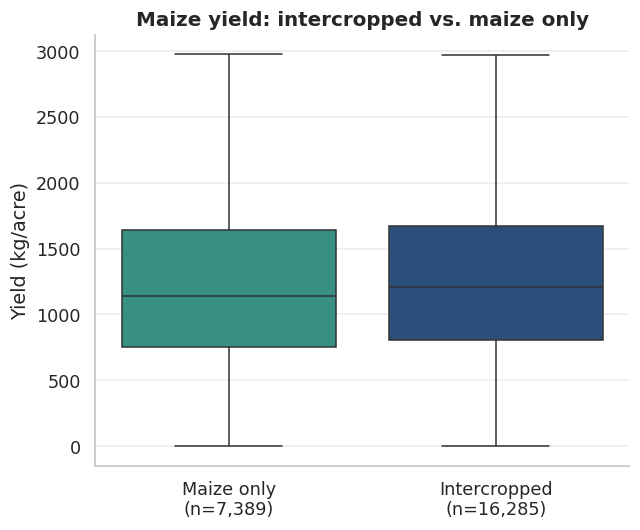

intercrop
False    1144.0
True     1206.0
Name: yield_kg_pa, dtype: float64


In [83]:
crop = df["intercrop"].map({False: "Maize only", True: "Intercropped"})
order = ["Maize only", "Intercropped"]
counts = crop.value_counts().reindex(order)
labels = [f"{g}\n(n={counts[g]:,})" for g in order]

plt.figure(figsize=(6, 5))
ax = sns.boxplot(x=crop, y=df["yield_kg_pa"], order=order, showfliers=False,
                 palette=["#1d4e89", "#2a9d8f"], hue=crop, legend=False)
ax.set_xticks(range(2))
ax.set_xticklabels(labels)
ax.set_title("Maize yield: intercropped vs. maize only")
ax.set_xlabel("")
ax.set_ylabel("Yield (kg/acre)")
plt.tight_layout()
save_chart("20_maize_yield_intercropped_vs_maize_only.png")
plt.show()

print(df.groupby("intercrop")["yield_kg_pa"].median().round(0))

Intercropping doesn't lower maize yield here. The intercropped farms come out slightly higher.

In [84]:
d = df.copy()
d["intercrop_f"] = d["intercrop"].astype(float)

g = (d.groupby(["district", "year", "intercrop_f"])["yield_kg_pa"]
       .agg(["median", "size"]).unstack("intercrop_f"))

keep = (g[("size", 0.0)] >= 20) & (g[("size", 1.0)] >= 20)
gap = g.loc[keep, ("median", 1.0)] - g.loc[keep, ("median", 0.0)]

print("district-year cells:", keep.sum())
print("share where intercropped is higher:", f"{(gap > 0).mean():.0%}")
print("median gap (kg/acre):", round(gap.median()))

district-year cells: 131
share where intercropped is higher: 50%
median gap (kg/acre): 0


intercropping has no effect once you compare within the district and year.

## Weed

In [85]:
print(df["weed"].value_counts(dropna=False))

weed
2.0    14101
NaN     3973
1.0     3972
3.0     1072
0.0      486
4.0       56
5.0       14
Name: count, dtype: int64


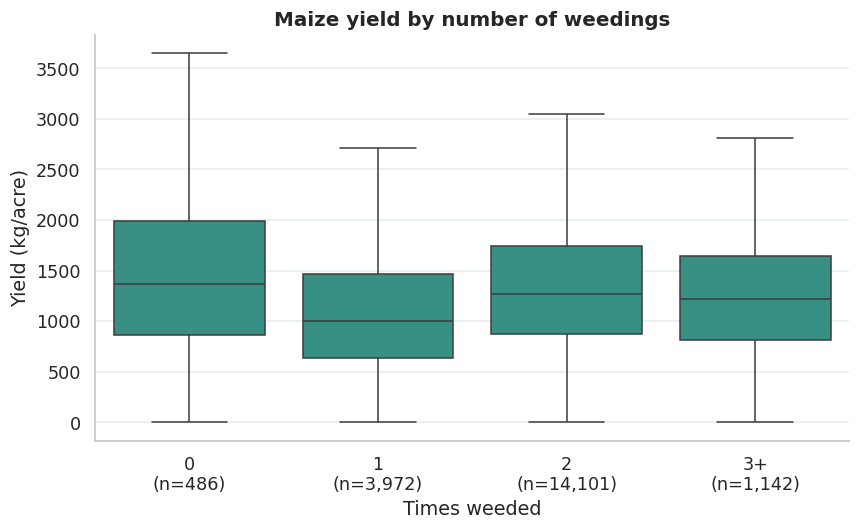

weed_group
0     1367.0
1     1000.0
2     1271.0
3+    1214.0
Name: yield_kg_pa, dtype: float64


In [86]:
w = df.dropna(subset=["weed"]).copy()
w["weed_group"] = w["weed"].clip(upper=3).map({0.0: "0", 1.0: "1", 2.0: "2", 3.0: "3+"})

order = ["0", "1", "2", "3+"]
counts = w["weed_group"].value_counts().reindex(order)
labels = [f"{g}\n(n={counts[g]:,})" for g in order]

plt.figure(figsize=(8, 5))
ax = sns.boxplot(data=w, x="weed_group", y="yield_kg_pa", order=order,
                 showfliers=False, color="#2a9d8f")
ax.set_xticks(range(4))
ax.set_xticklabels(labels)
ax.set_title("Maize yield by number of weedings")
ax.set_xlabel("Times weeded")
ax.set_ylabel("Yield (kg/acre)")
plt.tight_layout()
save_chart("21_maize_yield_by_number_of_weedings.png")
plt.show()

print(w.groupby("weed_group")["yield_kg_pa"].median().reindex(order).round(0))

In [87]:
w = df[df["weed"] >= 1].copy()
w["twice"] = (w["weed"] >= 2).astype(float)

g = (w.groupby(["district", "year", "twice"])["yield_kg_pa"]
       .agg(["median", "size"]).unstack("twice"))

keep = (g[("size", 0.0)] >= 20) & (g[("size", 1.0)] >= 20)
gap = g.loc[keep, ("median", 1.0)] - g.loc[keep, ("median", 0.0)]

print("district-year cells:", keep.sum())
print("share where 2+ weedings is higher:", f"{(gap > 0).mean():.0%}")
print("median gap (kg/acre):", round(gap.median()))

district-year cells: 57
share where 2+ weedings is higher: 81%
median gap (kg/acre): 179


In [88]:
w = df.dropna(subset=["weed"]).copy()
w["weed_group"] = w["weed"].clip(upper=3).map({0.0: "0", 1.0: "1", 2.0: "2", 3.0: "3+"})

print(w.groupby(["year", "weed_group"])["yield_kg_pa"]
        .agg(n="size", median="median").round(0).unstack("weed_group"))

              n                   median                        
weed_group    0     1     2   3+       0       1       2      3+
year                                                            
2017        329   969  2606   87  1379.0  1107.0  1433.0  1434.0
2018         54   972  2918  267  1623.0  1043.0  1237.0  1175.0
2019         25  1242  3881  219   998.0   936.0  1260.0  1234.0
2020         78   789  4696  569  1478.0   958.0  1234.0  1192.0


### Weeding and yield
Weeding at least twice goes with higher yield; weeding more than twice adds nothing.
- **Overall** in every year, farms weeding twice have a higher median than farms weeding once, by +194 to +326 kg/acre (about 20–30%). Three or more weedings match twice.

- I excluded **zero weedings:**. These farms have a higher median than farms weeding once in the larger cells (for example, 1,379 vs. 1,107 in 2017), which has no agronomic explanation, and the group is small (25 to 329 farms a year).

### Growing days

In [89]:
print(df["growing_days"].describe().round(0))
print(df.groupby("year")["growing_days"].median())
print((df["growing_days"] < 60).sum(), (df["growing_days"] > 300).sum())

count    16445.0
mean       153.0
std         32.0
min         63.0
25%        129.0
50%        149.0
75%        172.0
max        242.0
Name: growing_days, dtype: float64
year
2016      NaN
2017    142.0
2018    153.0
2019    148.0
2020    147.0
Name: growing_days, dtype: float64
0 0


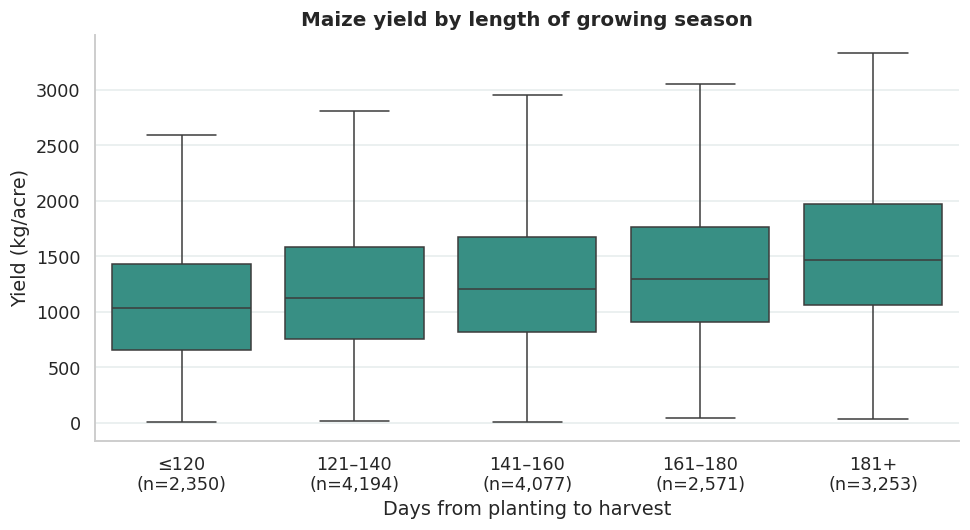

days_group
≤120       1034.0
121–140    1127.0
141–160    1200.0
161–180    1293.0
181+       1467.0
Name: yield_kg_pa, dtype: float64


In [104]:
days = df.dropna(subset=["growing_days"]).copy()
bins = [0, 120, 140, 160, 180, 250]
order = ["≤120", "121–140", "141–160", "161–180", "181+"]
days["days_group"] = pd.cut(days["growing_days"], bins=bins, labels=order)

counts = days["days_group"].value_counts().reindex(order)
labels = [f"{l}\n(n={counts[l]:,})" for l in order]

plt.figure(figsize=(9, 5))
ax = sns.boxplot(data=days, x="days_group", y="yield_kg_pa", order=order,
                 showfliers=False, color="#2a9d8f")
ax.set_xticks(range(len(order)))
ax.set_xticklabels(labels)
ax.set_title("Maize yield by length of growing season")
ax.set_xlabel("Days from planting to harvest")
ax.set_ylabel("Yield (kg/acre)")
plt.tight_layout()
save_chart("22_maize_yield_by_length_of_growing_season.png")
plt.show()

print(days.groupby("days_group", observed=True)["yield_kg_pa"].median().round(0))

Medians rise in every band. BUt a longer season might be a marker for a cooler climate so we need a district-year check.

In [91]:
days["long_season"] = (days["growing_days"] >= days["growing_days"].median()).astype(float)

days_agg = (days.groupby(["district", "year", "long_season"])["yield_kg_pa"]
       .agg(["median", "size"]).unstack("long_season"))

keep = (days_agg[("size", 0.0)] >= 20) & (days_agg[("size", 1.0)] >= 20)
gap = days_agg.loc[keep, ("median", 1.0)] - days_agg.loc[keep, ("median", 0.0)]

print("district-year cells:", keep.sum())
print("share where longer season is higher:", f"{(gap > 0).mean():.0%}")
print("median gap (kg/acre):", round(gap.median()))

district-year cells: 81
share where longer season is higher: 57%
median gap (kg/acre): 20


#### Length of growing season and yield

Season length has no effect on yield once place is controlled for.

- **Coverage:** 16,445 farms (2018–2020 mostly), with values from 63 to 242 days (median 149).
- **Overall:** median yield rises steadily from about 1,035 kg/acre for seasons of 120 days or less to about 1,465 for 181+ days, roughly +40%.
- **Within district and year:** farms with a season at or above the median (149 days) beat shorter-season farms in only 57% of 81 district-year cells (≥20 farms per side), with a median gap of +20 kg/acre.

Longer seasons occur in districts that yield more for other reasons, probably altitude and climate.

### Compost

In [92]:
print(df["compost"].value_counts(dropna=False))
print(df.groupby("year")["compost"].apply(lambda s: s.notna().mean()).round(2))

compost
0.0    13603
1.0     5764
NaN     4307
Name: count, dtype: int64
year
2016    1.00
2017    0.95
2018    0.60
2019    0.56
2020    0.99
Name: compost, dtype: float64


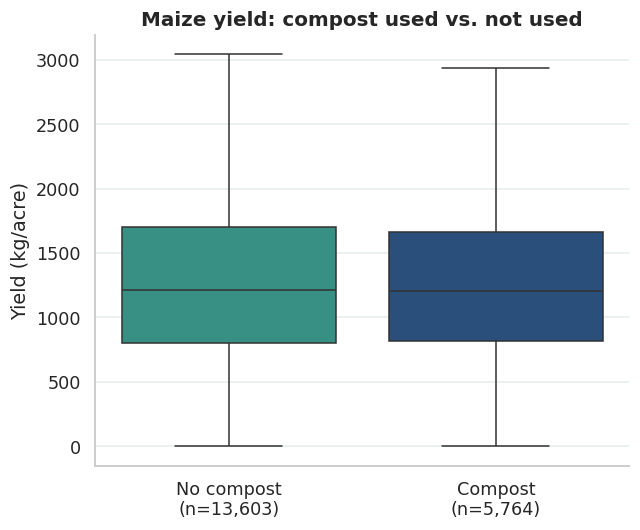

compost
0.0    1216.0
1.0    1202.0
Name: yield_kg_pa, dtype: float64


In [93]:
compost = df.dropna(subset=["compost"]).copy()
compost["compost_label"] = compost["compost"].map({0.0: "No compost", 1.0: "Compost"})
order = ["No compost", "Compost"]
counts = compost["compost_label"].value_counts().reindex(order)
labels = [f"{label}\n(n={counts[label]:,})" for label in order]

plt.figure(figsize=(6, 5))
ax = sns.boxplot(data=compost, x="compost_label", y="yield_kg_pa", order=order,
                 showfliers=False, palette=["#1d4e89", "#2a9d8f"],
                 hue="compost_label", legend=False)
ax.set_xticks(range(2))
ax.set_xticklabels(labels)
ax.set_title("Maize yield: compost used vs. not used")
ax.set_xlabel("")
ax.set_ylabel("Yield (kg/acre)")
plt.tight_layout()
save_chart("23_maize_yield_compost_used_vs_not_used.png")
plt.show()

print(compost.groupby("compost")["yield_kg_pa"].median().round(0))

Compost shows no difference in the raw comparison. The medians are almost identical

In [94]:
g = (compost.groupby(["district", "year", "compost"])["yield_kg_pa"]
            .agg(["median", "size"]).unstack("compost"))

keep = (g[("size", 0.0)] >= 20) & (g[("size", 1.0)] >= 20)
gap = g.loc[keep, ("median", 1.0)] - g.loc[keep, ("median", 0.0)]

print("district-year cells:", keep.sum())
print("share where compost is higher:", f"{(gap > 0).mean():.0%}")
print("median gap (kg/acre):", round(gap.median()))

district-year cells: 95
share where compost is higher: 77%
median gap (kg/acre): 124


Compost goes with higher yield, but only once you compare farms in the same district and year.

The raw plot showed nothing, but the comparison inside district-years finds +124 kg/acre, with 77% of 95 cells favouring compost.

In [95]:
dist = (compost.groupby("district")
               .agg(compost_share=("compost", "mean"),
                    median_yield=("yield_kg_pa", "median"),
                    n=("compost", "size")))
dist = dist[dist["n"] >= 30]

print("districts:", len(dist))
print("correlation (Spearman):", round(dist["compost_share"].corr(dist["median_yield"], method="spearman"), 2))

districts: 53
correlation (Spearman): -0.53


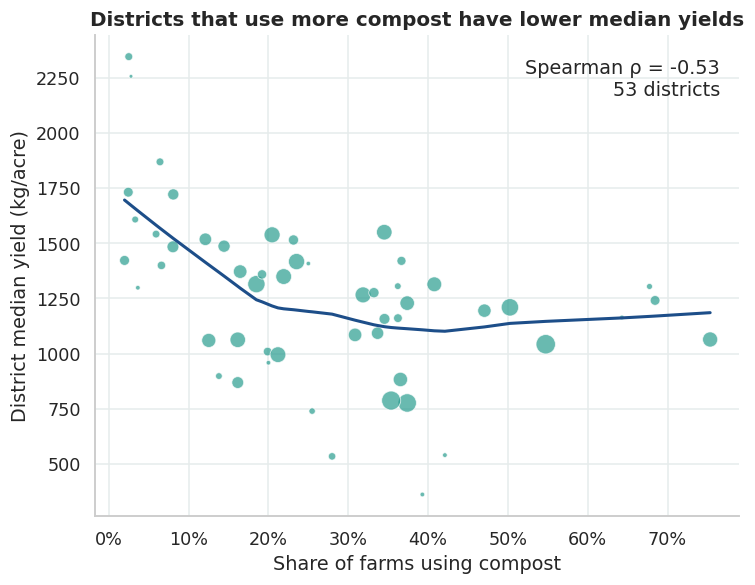

In [96]:
from scipy.stats import spearmanr

rho, _ = spearmanr(dist["compost_share"], dist["median_yield"])

plt.figure(figsize=(7, 5.5))
ax = sns.regplot(
    data=dist, x="compost_share", y="median_yield",
    scatter=False, lowess=True, line_kws={"color": "#1d4e89", "linewidth": 2},
)
ax.scatter(dist["compost_share"], dist["median_yield"],
           s=dist["n"] / 6, color="#2a9d8f", alpha=0.7,
           edgecolor="white", linewidth=0.6)

ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Districts that use more compost have lower median yields")
ax.set_xlabel("Share of farms using compost")
ax.set_ylabel("District median yield (kg/acre)")
ax.text(0.97, 0.95, f"Spearman ρ = {rho:.2f}\n{len(dist)} districts",
        transform=ax.transAxes, ha="right", va="top")
plt.tight_layout()
save_chart("24_districts_that_use_more_compost_have_lower_median_.png")
plt.show()

In [97]:
print(df["cows"].describe().round(1))
print(df["cows"].value_counts().head(8).sort_index())
print(df.groupby("year")["cows"].apply(lambda s: s.notna().mean()).round(2))

count    19263.0
mean         1.9
std          2.0
min          0.0
25%          0.0
50%          2.0
75%          3.0
max         25.0
Name: cows, dtype: float64
cows
0.0    5771
1.0    3645
2.0    4350
3.0    2469
4.0    1347
5.0     733
6.0     390
7.0     207
Name: count, dtype: int64
year
2016    1.00
2017    1.00
2018    0.00
2019    1.00
2020    0.97
Name: cows, dtype: float64


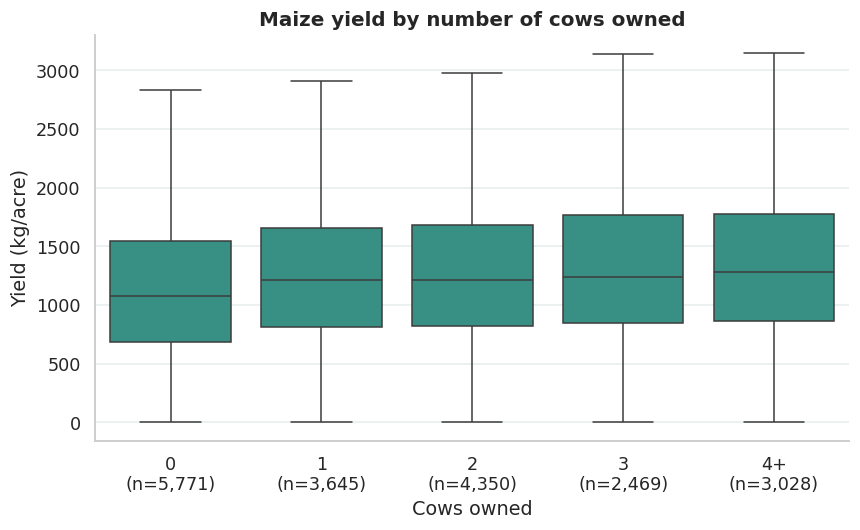

cow_group
0     1079.0
1     1211.0
2     1212.0
3     1242.0
4+    1283.0
Name: yield_kg_pa, dtype: float64


In [98]:
cw = df.dropna(subset=["cows"]).copy()
cw["cow_group"] = cw["cows"].clip(upper=4).map({0.0: "0", 1.0: "1", 2.0: "2", 3.0: "3", 4.0: "4+"})

order = ["0", "1", "2", "3", "4+"]
counts = cw["cow_group"].value_counts().reindex(order)
labels = [f"{g}\n(n={counts[g]:,})" for g in order]

plt.figure(figsize=(8, 5))
ax = sns.boxplot(data=cw, x="cow_group", y="yield_kg_pa", order=order,
                 showfliers=False, color="#2a9d8f")
ax.set_xticks(range(5))
ax.set_xticklabels(labels)
ax.set_title("Maize yield by number of cows owned")
ax.set_xlabel("Cows owned")
ax.set_ylabel("Yield (kg/acre)")
plt.tight_layout()
save_chart("25_maize_yield_by_number_of_cows_owned.png")
plt.show()

print(cw.groupby("cow_group")["yield_kg_pa"].median().reindex(order).round(0))

Owning any cow goes with about +13% but more cows add nothing.

In [99]:
print(df["cows_binary"].value_counts(dropna=False))
print(df.groupby("year")["cows_binary"].apply(lambda s: s.notna().mean()).round(2))
print(pd.crosstab(df["cows"].gt(0), df["cows_binary"], dropna=False))

cows_binary
NaN    13405
1.0     7141
0.0     3128
Name: count, dtype: int64
year
2016    0.00
2017    0.00
2018    1.00
2019    0.00
2020    0.97
Name: cows_binary, dtype: float64
cows_binary   0.0   1.0   NaN
cows                         
False        3128  3037  4017
True            0  4104  9388


Each column covers what the other lacks. SO gonna combine them to beef up (lol) the cows_binary column since the yield difference only shows up when you go from 0 to 1.

In [100]:
df["owns_cow"] = np.where(df["cows"].notna(), df["cows"].gt(0).astype(float), df["cows_binary"])

both = df[df["year"] == 2020].dropna(subset=["cows", "cows_binary"])
print(pd.crosstab(both["cows"].gt(0), both["cows_binary"]))
print(df.groupby("year")["owns_cow"].agg(recorded="count", share_owning="mean").round(2))

cows_binary   0.0   1.0
cows                   
False        1920     0
True            0  4104
      recorded  share_owning
year                        
2016      3876          0.72
2017      3991          0.73
2018      4245          0.72
2019      5372          0.69
2020      6024          0.68


In [101]:
cw = df.dropna(subset=["owns_cow"])

g = (cw.groupby(["district", "year", "owns_cow"])["yield_kg_pa"]
       .agg(["median", "size"]).unstack("owns_cow"))

keep = (g[("size", 0.0)] >= 20) & (g[("size", 1.0)] >= 20)
gap = g.loc[keep, ("median", 1.0)] - g.loc[keep, ("median", 0.0)]

print("district-year cells:", keep.sum())
print("share where cow owners are higher:", f"{(gap > 0).mean():.0%}")
print("median gap (kg/acre):", round(gap.median()))

pct_gap = ((g.loc[keep, ("median", 1.0)] - g.loc[keep, ("median", 0.0)])
           / g.loc[keep, ("median", 0.0)] * 100)

print("median gap (%):", round(pct_gap.median(), 1))

district-year cells: 134
share where cow owners are higher: 81%
median gap (kg/acre): 120
median gap (%): 11.1


Farms that own at least one cow yield about 11% more, and the gap holds within district and year.

In [102]:
rest = [
    # household and wealth
    "hh_num", "hh_num_under5", "hh_num_under18", "electricity",
    "chickens", "chicks", "goats", "sheep", "pigs", "ducks", "rabbits", "guinea_fowl", "oxen",
    "chicken_binary", "goats_binary", "radio_binary", "bikes_binary",
    # management and inputs
    "pesticide", "basal_method", "lime_method", "comp_method", "seed_type",
    "npk_kg_pa", "comp_source", "comp_source_manure", "comp_kg_pa", "comp_wb_pa",
    "prev_season_dap_kg", "prev_season_can_kg", "prev_season_urea_kg",
    "prev_season_npk_kg", "prev_season_lime_kg",
    # other pests and diseases
    "pest_disease", "mlnd", "cutworms", "msv", "aphids", "blight",
    # timing, spacing, location
    "plant_date", "harvest_date", "seed_depth_est", "row_spacing", "plant_spacing",
    "plants_sqm_spacing", "distance_meter", "slope_angle_num", "slope_angle_des",
]

rows = []
for c in rest:
    cov = df.groupby("year")[c].apply(lambda x: x.notna().mean())
    rows.append({
        "column": c,
        "dtype": str(df[c].dtype),
        "n_unique": df[c].nunique(),
        "non_missing": round(df[c].notna().mean(), 2),
        "years_70pct+": ", ".join(str(y) for y in cov.index if cov[y] >= 0.7),
    })

print(pd.DataFrame(rows).to_string(index=False))

             column   dtype  n_unique  non_missing                 years_70pct+
             hh_num float64        21         1.00 2016, 2017, 2018, 2019, 2020
      hh_num_under5 float64         8         0.67             2018, 2019, 2020
     hh_num_under18 float64        17         1.00 2016, 2017, 2018, 2019, 2020
        electricity float64         2         0.82       2016, 2018, 2019, 2020
           chickens float64        65         0.65             2017, 2019, 2020
             chicks float64        53         0.40                   2017, 2019
              goats float64        22         0.65             2017, 2019, 2020
              sheep float64        19         0.40                   2017, 2019
               pigs float64        13         0.40                   2017, 2019
              ducks float64        18         0.40                   2017, 2019
            rabbits float64        18         0.40                   2017, 2019
        guinea_fowl float64        12   

In [103]:
variety_counts = df["seed_combo"].value_counts()
print("distinct combinations:", len(variety_counts))
print(variety_counts.head(20))
print("share of farms covered by the top 20:", round(variety_counts.head(20).sum() / variety_counts.sum(), 2))


distinct combinations: 236
seed_combo
h6213                4632
local                4010
dk8031               2738
h614d                2164
wh505                1938
otherhybrid          1849
scduma43             1391
h6218                 456
pan691                438
wh509                 383
pioneerp3812w         364
scsimba61             314
scpundamilia53        228
dk9089                224
dk777                 195
pn15                  185
sctembo73             167
dk8031+local          143
local+otherhybrid     118
p3812w                108
Name: count, dtype: int64
share of farms covered by the top 20: 0.93


# Conclusions

I looked at about 24,000 maize farms in Kenya from 2016 to 2020. The typical farm harvests around 1,200 kg per acre, but farms vary enormously, from nothing at all to 3,000 and above. This notebook answers what separates the good harvests from the bad ones.

## What makes the biggest difference
The seed a farmer plants, how fertile the field is, and whether they use DAP fertilizer are the main drivers. In each case I compared farms in the same district and the same year, so a good district or a good season can't explain the gap. The results held up.

| Factor | Comparison | How often the gap went the expected way | Typical gap (kg/acre) |
|---|---|---|---|
| Hybrid seed | named hybrid vs. local only | [update: cell 49] | [update: cell 49] |
| Field fertility | better vs. worse than the farmer's other fields | 96% of 26 district-years | +346 |
| DAP | used vs. not used | 95% of 60 district-years | +283 |
| Drought | reported vs. not | 75% of 64 district-years | −90 |
| Flood | reported vs. not | 65% of 51 district-years | −64 |

- **Seed, soil and DAP each add roughly 300 kg per acre:** A farm with hybrid seed and DAP gets about [update: cell 48]% more than one with local seed and no DAP.
- **One 50 kg bag of DAP per acre is where it pays off:** Small amounts under 25 kg do little, and using more than 50 kg gains nothing extra.
- **Drought and flood hurt, but less than you'd think:** Drought first looked like it cost 225 kg per acre, but half of that was because drought-prone districts yield less anyway. Once I compared farms in the same place, the cost fell to about 90 kg. Flood costs about 64 kg, and not consistently from year to year.
- **Where a farm is matters, but not by a lot:** District alone explains 18% of the differences in yield. Medians range from about 700 to 1,750 kg per acre across the larger districts, and yields tend to rise from west to east. The other 82% comes from differences between farms in the same district.

## What I couldn't find

- **Pests.** Fall armyworm, striga and stemborer show no clear effect. That doesn't mean they're harmless. They were only recorded in 2020, farmers just said yes or no without rating how bad it was, and some years only listed affected farms.
- **Urea and NPK.** Too few farmers use them (497 and 58) to say anything.
- **Plot size and year.** Weak patterns on their own.
- **Slope.** Only 19% of farms have it recorded, so I left it out.

## Things to keep in mind

- **This shows what goes with higher yields, not proof of what causes them:** Farmers who use hybrid seed or DAP may differ in other ways I can't see.
- **The data is mostly western Kenya: ** A few eastern clusters are too small to learn from.
- **Several answers come from the farmers themselves.** Drought, flood, pests and field fertility are all self-reported. Fertility is also relative to the farmer's other fields, and farmers may have answered it after harvest, when a poor crop could colour their view.
- **Seed type comes from the variety names:** The survey's own hybrid flag mislabelled about 1,500 farms, so I used the names instead. The 6% of farms that plant a mix of varieties are left out of the hybrid comparison.
- **I removed some impossible values:** DAP, CAN and urea rates above 200 kg per acre were set to missing. Most came from tiny plots in 2020.

## What to do next

1. Build a model with seed, fertility, DAP, drought and district together, and see how much of the variation they explain as a group.
2. Check whether the factors work together, for example whether DAP helps more on hybrid seed or on better fields.
3. Look at the farms that harvested nothing, separately from the rest.